In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [ ]:
# Upload Titanic dataset

from google.colab import files

uploaded = files.upload()

Saving gender_submission.csv to gender_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv


In [ ]:
# Load the dataset

df = pd.read_csv("train.csv")

# Display first 5 rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# Display dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 12)

Column Names:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# Select input features

X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

# Select target
y = df['Survived']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [ ]:
# Handle missing values

# Fill missing Age values with median
X['Age'] = X['Age'].fillna(X['Age'].median())

# Fill missing Embarked values with most frequent value
X['Embarked'] = X['Embarked'].fillna(X['Embarked'].mode()[0])

print("Missing values after handling:")
print(X.isnull().sum())

Missing values after handling:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


/tmp/ipykernel_864/1562874973.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Age'] = X['Age'].fillna(X['Age'].median())
/tmp/ipykernel_864/1562874973.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Embarked'] = X['Embarked'].fillna(X['Embarked'].mode()[0])


In [ ]:
# Convert categorical columns into numerical values

X = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True)

print("Features after encoding:")
print(X.head())

print("\nNew feature names:")
print(X.columns)

Features after encoding:
   Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  Embarked_S
0       3  22.0      1      0   7.2500      True       False        True
1       1  38.0      1      0  71.2833     False       False       False
2       3  26.0      0      0   7.9250     False       False        True
3       1  35.0      1      0  53.1000     False       False        True
4       3  35.0      0      0   8.0500      True       False        True

New feature names:
Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q',
       'Embarked_S'],
      dtype='object')


In [ ]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (712, 8)
Testing data: (179, 8)


In [ ]:
# Create Decision Tree without pruning

dt_unpruned = DecisionTreeClassifier(random_state=42)

# Train the model
dt_unpruned.fit(X_train, y_train)

print("Unpruned Decision Tree trained successfully.")

Unpruned Decision Tree trained successfully.


In [ ]:
# Make predictions using unpruned tree

y_pred_unpruned = dt_unpruned.predict(X_test)

print("Predictions:")
print(y_pred_unpruned[:10])

Predictions:
[0 0 0 0 1 0 1 1 0 0]


In [ ]:
# Calculate accuracy of unpruned tree

accuracy_unpruned = accuracy_score(y_test, y_pred_unpruned)

print("Accuracy of Unpruned Decision Tree:",
      accuracy_unpruned)

Accuracy of Unpruned Decision Tree: 0.8212290502793296


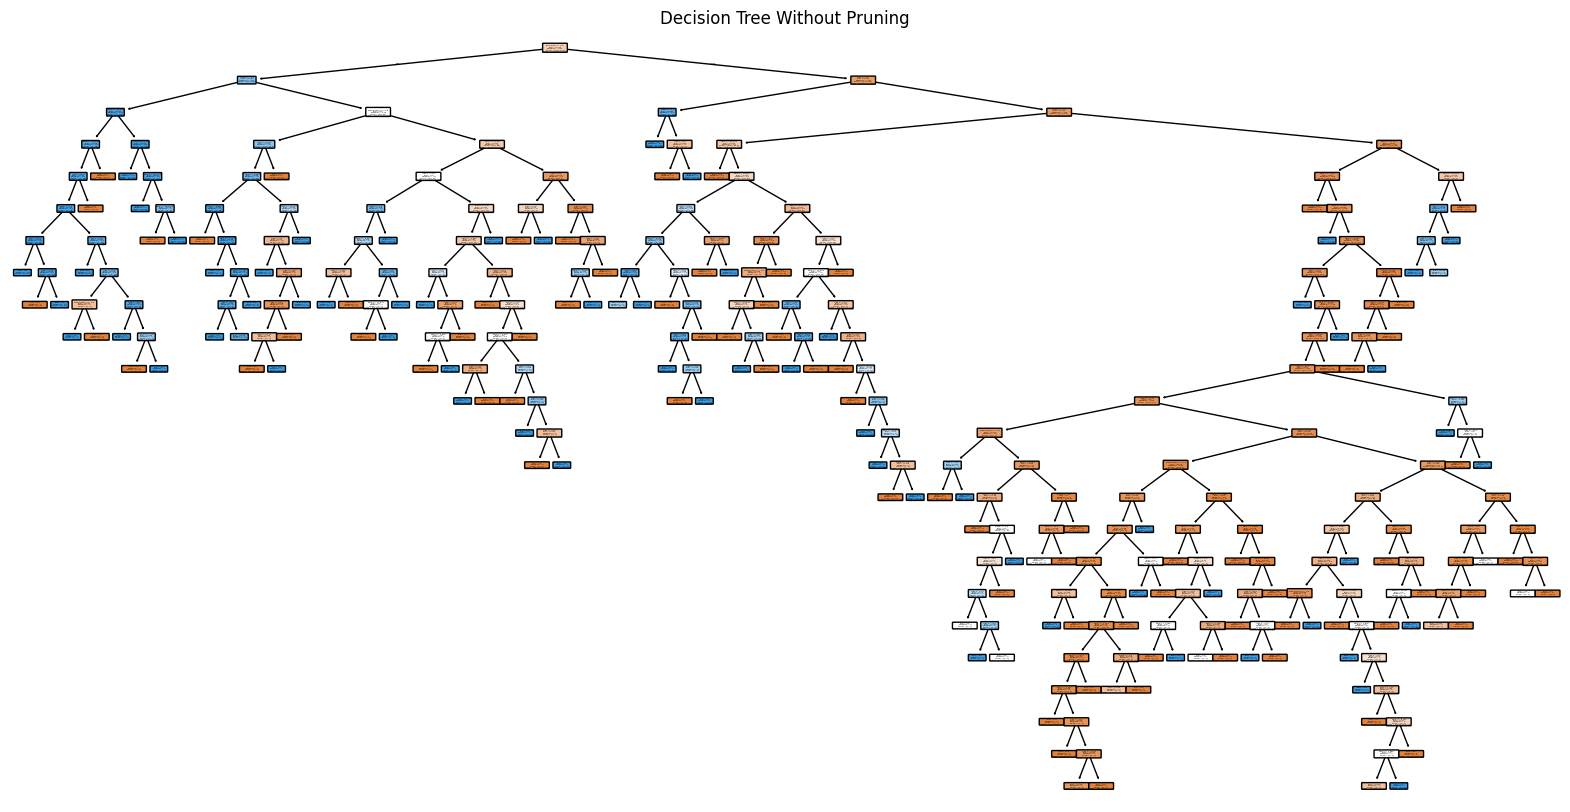

In [ ]:
# Visualize the unpruned decision tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_unpruned,
    feature_names=X.columns,
    class_names=['Did Not Survive', 'Survived'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Without Pruning")
plt.show()

In [ ]:
# Create Decision Tree with pruning parameters

dt_pruned = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

# Train the pruned tree
dt_pruned.fit(X_train, y_train)

print("Pruned Decision Tree trained successfully.")

Pruned Decision Tree trained successfully.


In [ ]:
# Make predictions using pruned tree

y_pred_pruned = dt_pruned.predict(X_test)

print("Predictions:")
print(y_pred_pruned[:10])

Predictions:
[0 0 0 0 1 0 1 0 0 0]


In [ ]:
# Calculate accuracy of pruned tree

accuracy_pruned = accuracy_score(y_test, y_pred_pruned)

print("Accuracy of Pruned Decision Tree:",
      accuracy_pruned)

Accuracy of Pruned Decision Tree: 0.776536312849162


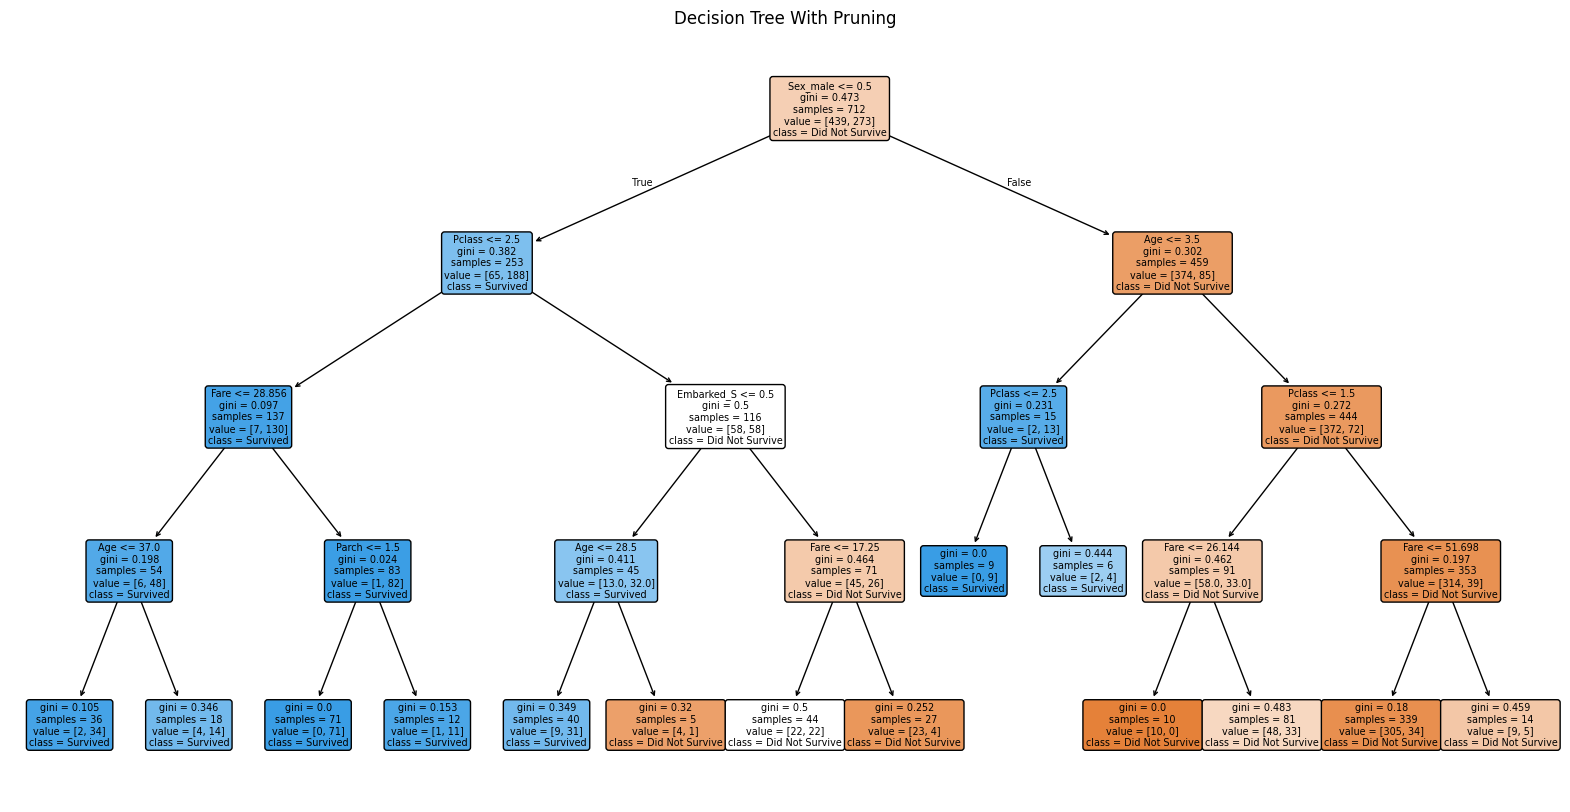

In [ ]:
# Visualize the pruned decision tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_pruned,
    feature_names=X.columns,
    class_names=['Did Not Survive', 'Survived'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree With Pruning")
plt.show()

In [ ]:
# Compare accuracy of both trees

print("Unpruned Tree Accuracy:",
      accuracy_unpruned)

print("Pruned Tree Accuracy:",
      accuracy_pruned)

Unpruned Tree Accuracy: 0.8212290502793296
Pruned Tree Accuracy: 0.776536312849162


In [ ]:
# Create accuracy comparison table

accuracy_comparison = pd.DataFrame({
    'Model': ['Without Pruning', 'With Pruning'],
    'Accuracy': [accuracy_unpruned, accuracy_pruned]
})

accuracy_comparison

,Model,Accuracy
0,Without Pruning,0.821229
1,With Pruning,0.776536


In [ ]:
# Get feature importance from pruned tree

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_pruned.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
      Feature  Importance
5    Sex_male    0.593517
0      Pclass    0.206451
1         Age    0.105275
4        Fare    0.055615
7  Embarked_S    0.038309
3       Parch    0.000833
2       SibSp    0.000000
6  Embarked_Q    0.000000


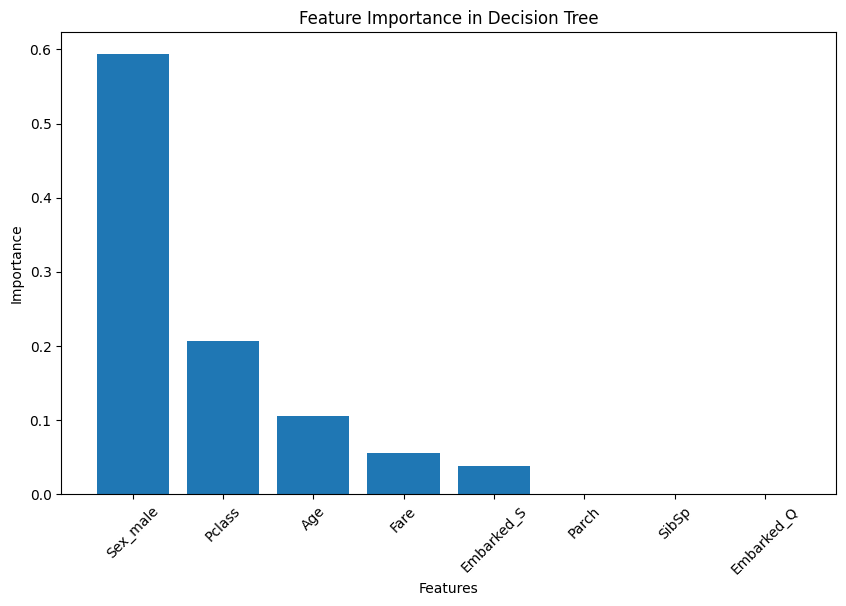

In [ ]:
# Plot feature importance

plt.figure(figsize=(10, 6))

plt.bar(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance in Decision Tree")
plt.xticks(rotation=45)

plt.show()